In [1]:
import pandas as pd 
from statsforecast import StatsForecast

from statsforecast.models import (
    AutoARIMA,
    AutoETS,
    AutoCES,
    AutoTheta,
    ARIMA,
    AutoRegressive,
    OptimizedTheta,
    DynamicTheta,
    DynamicOptimizedTheta,
    MSTL,
    GARCH,
    ARCH,
    HistoricAverage,
    Naive,
    RandomWalkWithDrift,
    SeasonalNaive,
    WindowAverage,
    SeasonalWindowAverage,
    SimpleExponentialSmoothingOptimized,
    SeasonalExponentialSmoothingOptimized,
    Holt,
    HoltWinters, 
)

import matplotlib.pyplot as plt
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mse 

/Users/annamcgurk/miniforge3/envs/forecasting_internship/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#importing and reading the ambulance response data
df = pd.read_csv("data/Daily_Responses_5_Years_2019_full.csv")
df.head()

,ds,y,area
0,2013-12-30,220,Cornwall
1,2013-12-30,129,Gloucestershire
2,2013-12-30,255,Wiltshire
3,2013-12-30,2042,Trust
4,2013-12-30,336,Dorset


In [3]:
#renaming area column to allow forecasting to work
df_rename = df.rename(columns={'area':'unique_id'}).copy()
df_rename.head()
#filtering to Trust area
Trust = df_rename[df_rename["unique_id"]=="Trust"]


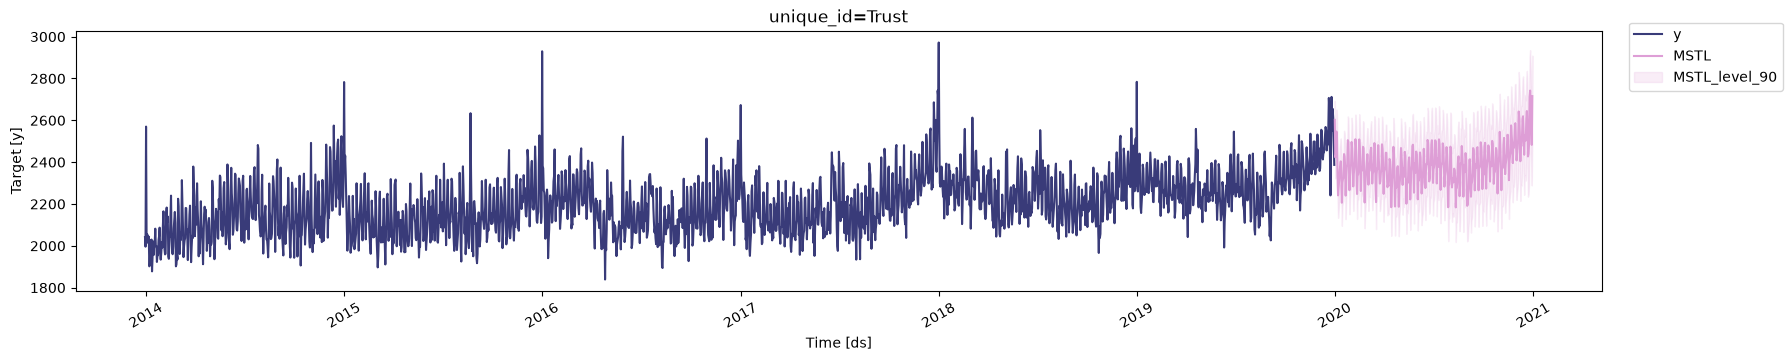

In [13]:
# making the fitted model
models = [MSTL(
    season_length=[7,365],
    trend_forecaster=AutoARIMA()
)]

sf = StatsForecast(
    models=models,
    freq='D'
)
sf.fit(df=Trust)

# making the predicted model
forecast_df = sf.predict(
    h=365, level=[90]
)
forecast_df.tail()

# plot the forecast
sf.plot(Trust,forecast_df, level=[90])


In [66]:
# training the model for many series 
# list of models 

models = [
    SeasonalNaive(season_length=365),
    AutoTheta(season_length=365),
    HoltWinters(season_length=365),
    HistoricAverage(),
    MSTL(season_length=[7,365]),
]

sf = StatsForecast(
    models=models,
    freq='D',
    fallback_model=SeasonalNaive(season_length=365),
    n_jobs=-1
)

forecasts_df = sf.forecast(df=Trust, h=365, level=[90])
forecasts_df.head()



,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-90,SeasonalNaive-hi-90,AutoTheta,AutoTheta-lo-90,AutoTheta-hi-90,HoltWinters,HoltWinters-lo-90,HoltWinters-hi-90,HistoricAverage,HistoricAverage-lo-90,HistoricAverage-hi-90,MSTL,MSTL-lo-90,MSTL-hi-90
0,Trust,2020-01-01,2784.0,2545.828613,3022.171387,2400.841064,2212.358154,2602.158203,2744.033936,2540.203857,2947.864014,2202.15332,1969.71106,2434.595459,2617.112305,2519.970215,2714.254150
1,Trust,2020-01-02,2277.0,2038.828491,2515.171387,2179.419922,1943.706665,2391.914307,2505.258789,2301.428955,2709.088867,2202.15332,1969.71106,2434.595459,2415.005127,2313.252441,2516.758057
2,Trust,2020-01-03,2260.0,2021.828491,2498.171387,2085.447998,1756.883667,2404.204102,2405.708984,2201.878662,2609.539062,2202.15332,1969.71106,2434.595459,2393.959717,2287.796143,2500.123291
3,Trust,2020-01-04,2349.0,2110.828613,2587.171387,2062.531250,1685.715576,2392.129639,2383.062988,2179.232666,2586.893066,2202.15332,1969.71106,2434.595459,2503.865479,2393.467285,2614.263916
4,Trust,2020-01-05,2369.0,2130.828613,2607.171387,2011.649536,1617.510864,2395.007812,2332.797852,2128.967529,2536.628418,2202.15332,1969.71106,2434.595459,2438.401855,2323.925293,2552.878174


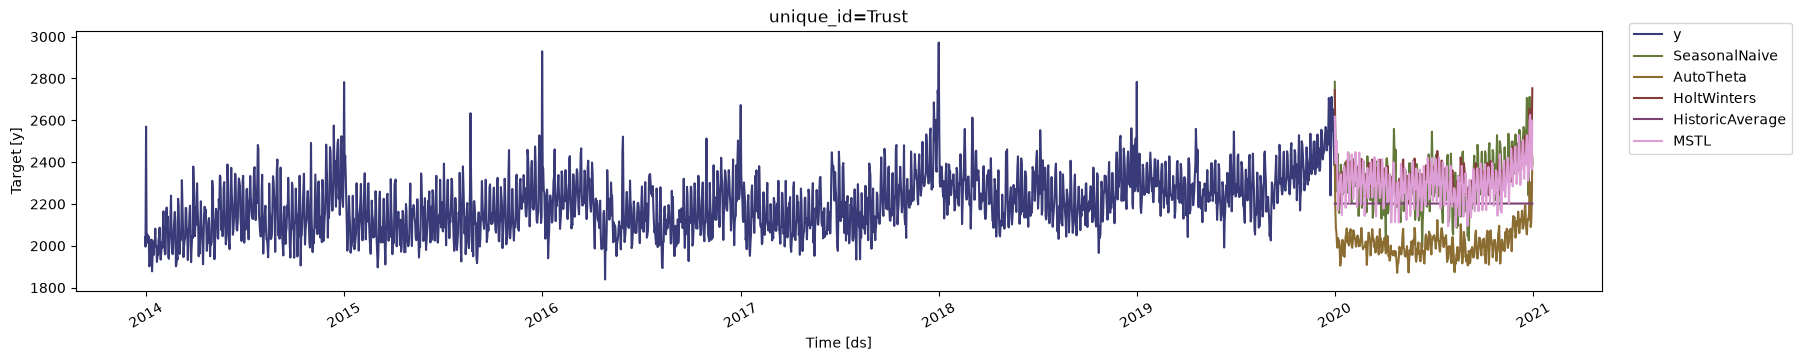

In [15]:
sf.plot(Trust,forecasts_df)

In [16]:
#cross validating the models
cv_df = sf.cross_validation(
    df = Trust,
    h=365, #forecasts 365 days ahead
    step_size=182, #moves the window 182 days ahead before each forecast
    n_windows=5, #evaluates 7 windows
)

cv_df.head()

,unique_id,ds,cutoff,y,SeasonalNaive,AutoTheta,HoltWinters,HistoricAverage,MSTL
0,Trust,2017-01-03,2017-01-02,2280.0,2265.0,2350.972412,2287.020996,2151.933594,2152.381592
1,Trust,2017-01-04,2017-01-02,2220.0,2254.0,2351.048584,2223.115967,2151.933594,2118.221436
2,Trust,2017-01-05,2017-01-02,2128.0,2134.0,2351.125000,2116.107178,2151.933594,2151.009766
3,Trust,2017-01-06,2017-01-02,2114.0,2034.0,2351.201172,1997.861572,2151.933594,2082.406494
4,Trust,2017-01-07,2017-01-02,2303.0,2160.0,2351.277588,2087.608154,2151.933594,2160.003906


In [17]:
# scoring each models evaluation 
def evaluate_cv(Trust, metric):
    models = Trust.columns.drop(['unique_id', 'ds', 'y', 'cutoff']).tolist()
    evals = evaluate(Trust, metrics=[metric], models=models)
    evals = evals.drop(columns=['metric'])
    evals['best_model'] = evals[models].idxmin(axis=1)
    return evals

# create a dataframe with the evaluation of cross-validation using a MSE metric
evaluation_df = evaluate_cv(cv_df, mse)
evaluation_df.head() 


,unique_id,cutoff,SeasonalNaive,AutoTheta,HoltWinters,HistoricAverage,MSTL,best_model
0,Trust,2017-01-02,23117.212891,47185.921875,26636.789062,22753.558594,11296.505859,MSTL
1,Trust,2017-07-03,27255.478516,22169.806641,28501.097656,28340.511719,13777.846680,MSTL
2,Trust,2018-01-01,24237.630859,35851.910156,20418.470703,21301.275391,31904.238281,HoltWinters
3,Trust,2018-07-02,17874.210938,25754.205078,20126.935547,19520.003906,10691.775391,MSTL
4,Trust,2018-12-31,20934.613281,203252.234375,24660.210938,30851.617188,47829.656250,SeasonalNaive


In [18]:
# creating a summary table for my evaluation 
evaluation_df['best_model'].value_counts().to_frame().reset_index()

,best_model,count
0,MSTL,3
1,HoltWinters,1
2,SeasonalNaive,1


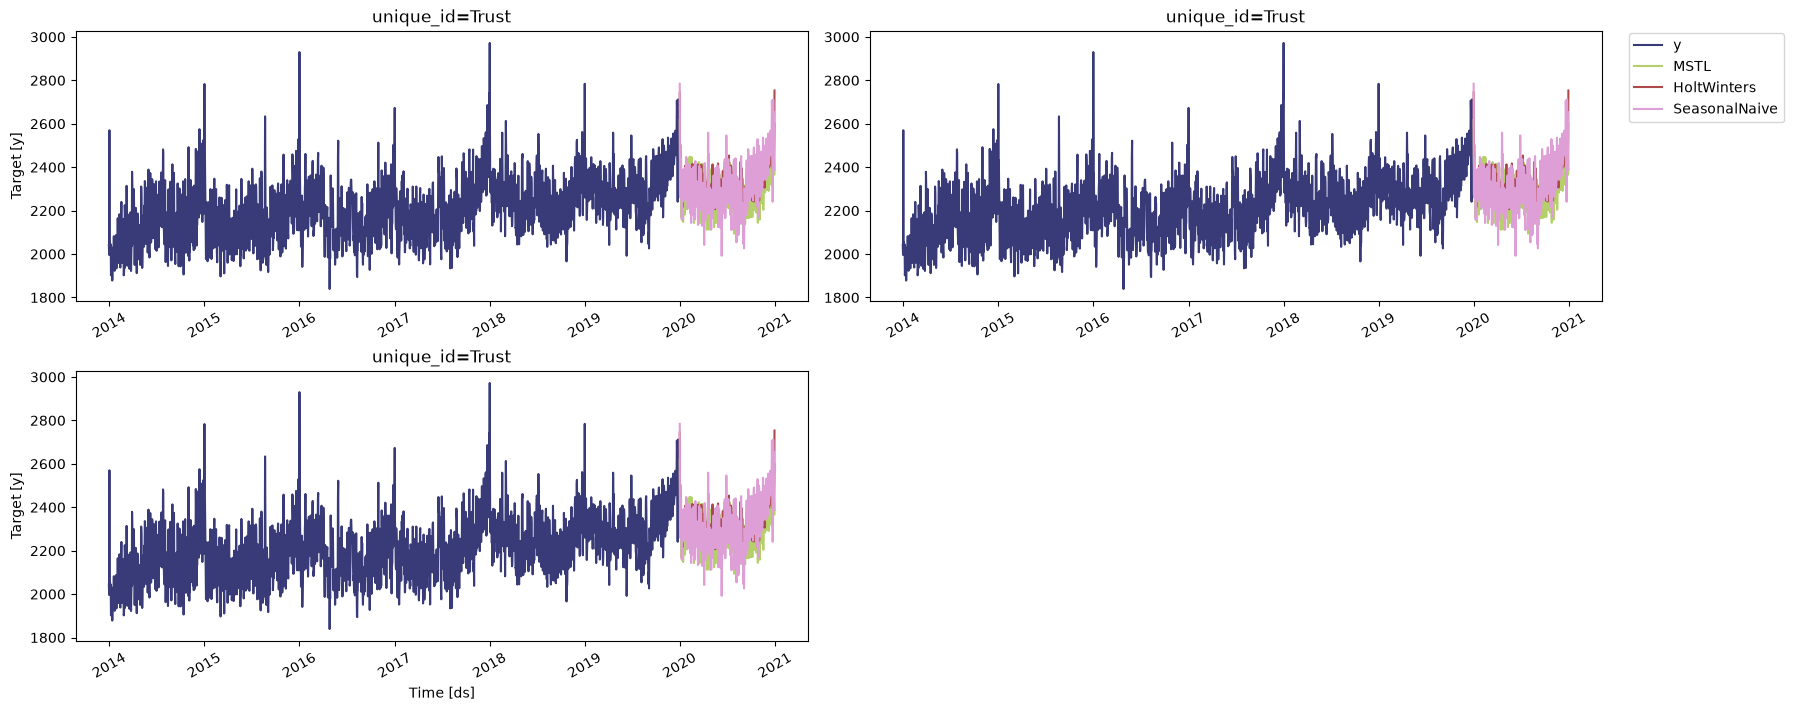

In [19]:
#plotting the unique_ids where a specific model wins
seasonal_ids = evaluation_df.query('best_model=="MSTL"')['unique_id']
sf.plot(Trust,forecasts_df,unique_ids=seasonal_ids, models=["MSTL","HoltWinters","SeasonalNaive"])

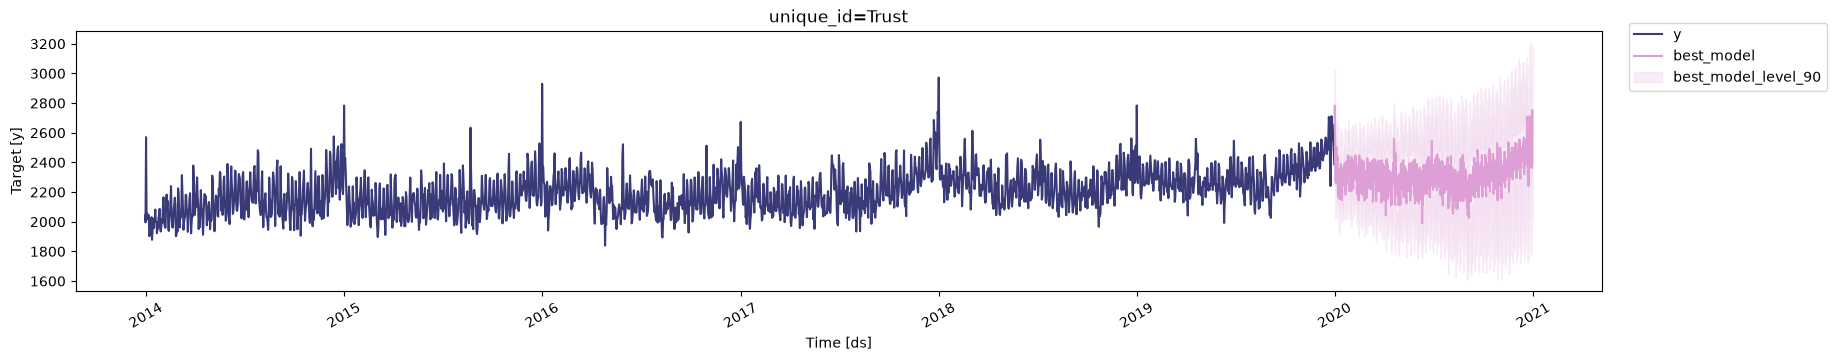

In [20]:
#making a dataframe with the best possible forecast for each unique_id
def get_best_model_forecast(forecasts_df,evaluation_df):
    with_best=forecasts_df.merge(evaluation_df[['unique_id','best_model']])
    res = with_best[['unique_id','ds']].copy()
    for suffix in ('', '-lo-90','-hi-90'):
        res[f'best_model{suffix}'] = with_best.apply(lambda row: row[row['best_model'] + suffix],axis=1)
    return res

prod_forecasts_df = get_best_model_forecast(forecasts_df,evaluation_df)
prod_forecasts_df.head()

sf.plot(Trust, prod_forecasts_df, level=[90])

# Including all areas and all models that have no reason to be excluded

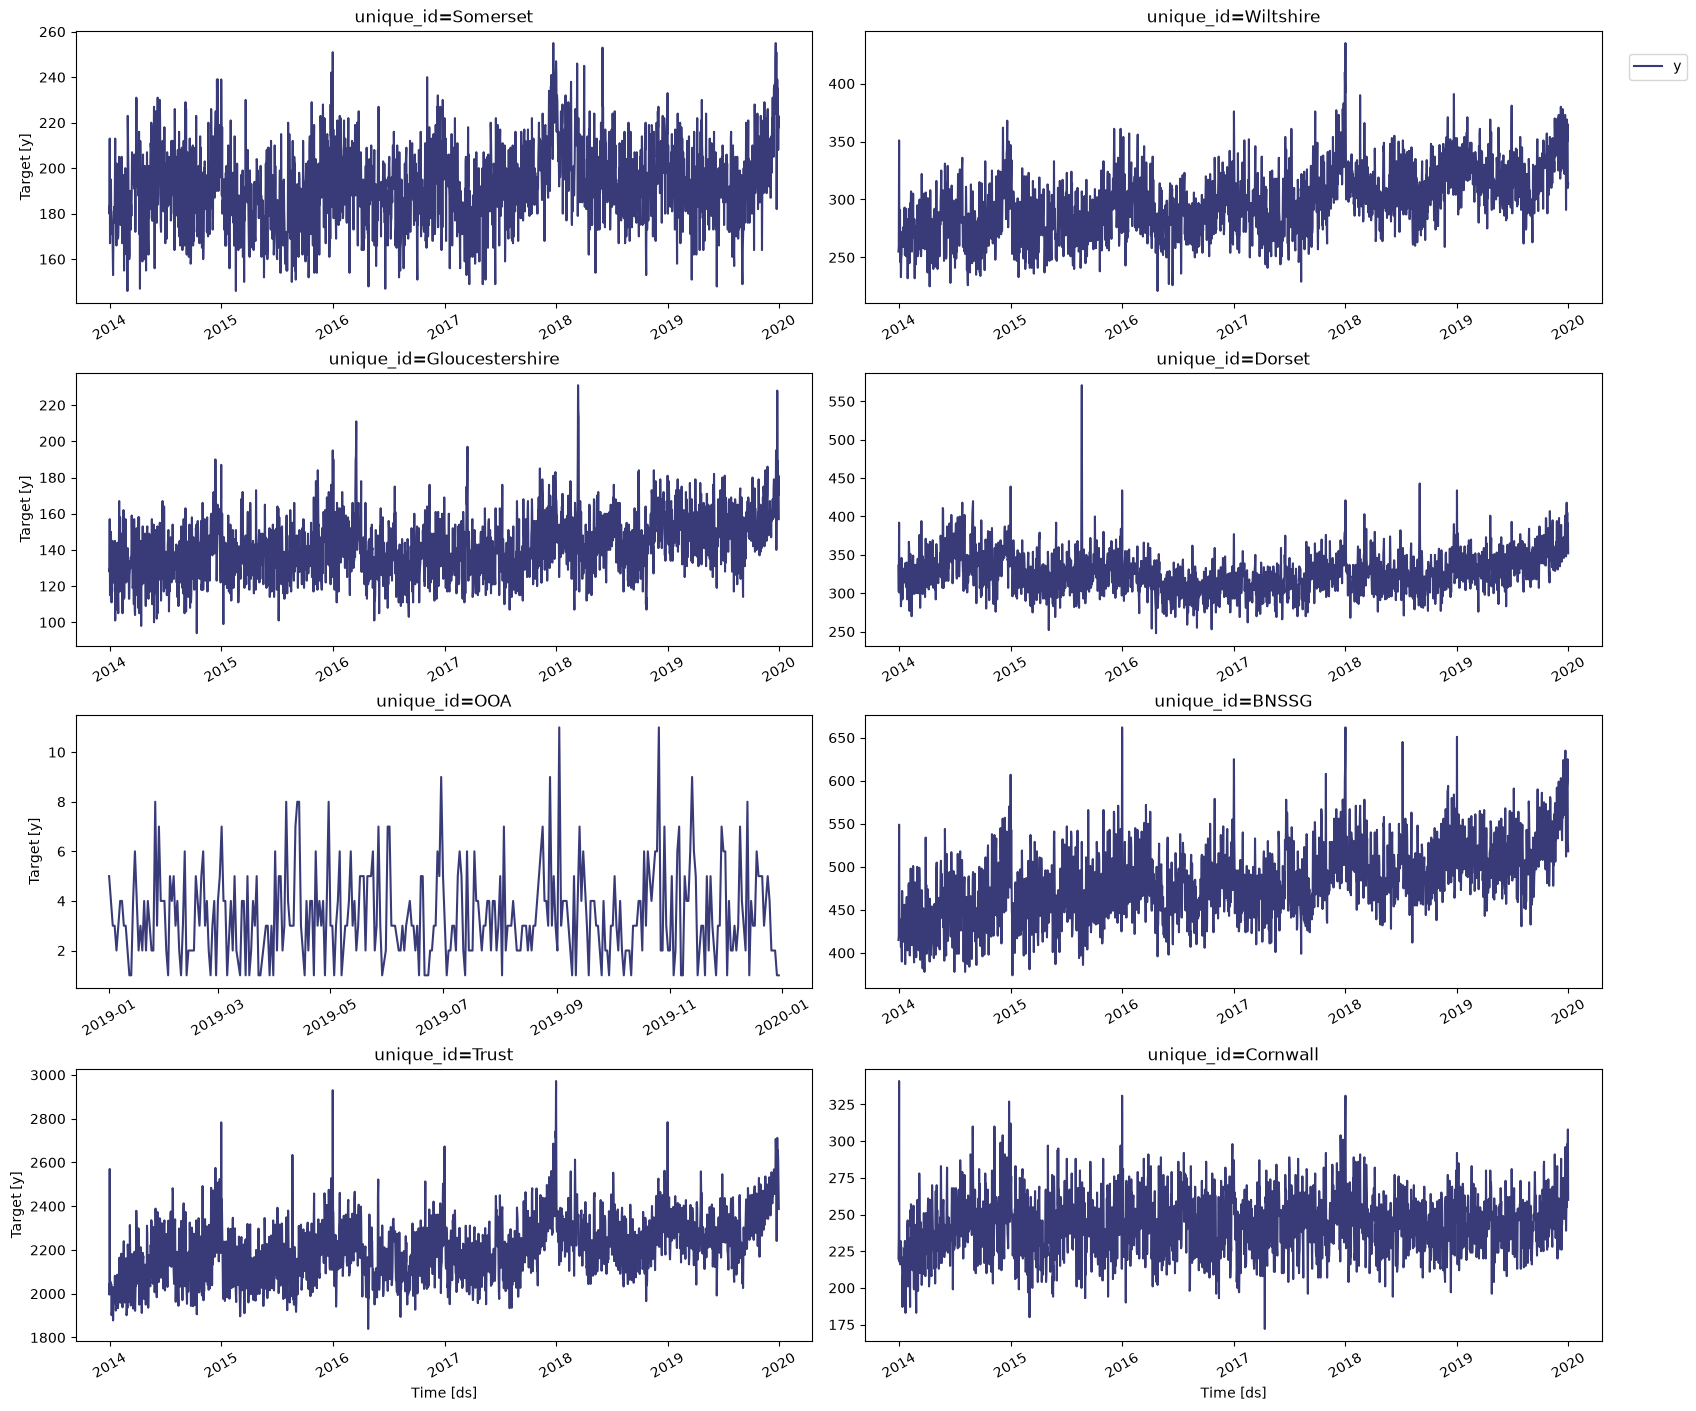

In [ ]:
# exploring all of the data
StatsForecast.plot(df_rename)

In [ ]:
# training the model for many series 
# list of models 

df_filtered = df_rename[df_rename['unique_id'] != 'OOA']

models = [
    AutoTheta(season_length=365),
    OptimizedTheta(season_length=365),
    DynamicTheta(season_length=365),
    DynamicOptimizedTheta(season_length=365),
    MSTL(season_length=[7,365]),
    GARCH(),
    ARCH(),
    HistoricAverage(),
    Naive(),
    RandomWalkWithDrift(),
    SeasonalNaive(season_length=365),
    WindowAverage(window_size=7),
    SeasonalWindowAverage(season_length=365, window_size=3),
    SimpleExponentialSmoothingOptimized(),
    SeasonalExponentialSmoothingOptimized(season_length=365),
    Holt(season_length=365),
    HoltWinters(season_length=365),
]


sf = StatsForecast(
    models=models,
    freq='D',
    fallback_model=SeasonalNaive(season_length=365),
    n_jobs=1
)

forecasts_df = sf.forecast(df=df_filtered, h=365, level=[90])
display(forecasts_df.head())
display(forecasts_df.tail())



,unique_id,ds,AutoTheta,AutoTheta-lo-90,AutoTheta-hi-90,OptimizedTheta,OptimizedTheta-lo-90,OptimizedTheta-hi-90,DynamicTheta,DynamicTheta-lo-90,...,SESOpt-hi-90,SeasESOpt,SeasESOpt-lo-90,SeasESOpt-hi-90,Holt,Holt-lo-90,Holt-hi-90,HoltWinters,HoltWinters-lo-90,HoltWinters-hi-90
0,BNSSG,2020-01-01,655.517456,599.079773,715.798096,655.517456,599.079773,715.798096,655.293884,598.783936,...,722.542114,651.0,579.457886,722.542114,572.572327,517.943481,627.201172,631.052551,572.521667,689.583435
1,BNSSG,2020-01-02,576.731445,526.776733,630.973999,576.731445,526.776733,630.973999,576.515137,526.496216,...,570.542114,499.0,427.457916,570.542114,572.661743,517.764343,627.559204,558.448914,499.917999,616.979797
2,BNSSG,2020-01-03,554.044006,500.588593,601.469543,554.044006,500.588593,601.469543,553.817444,500.293182,...,569.542114,498.0,426.457916,569.542114,572.751221,517.585938,627.916504,540.205200,481.674316,598.736145
3,BNSSG,2020-01-04,531.570862,475.151306,580.132202,531.570862,475.151306,580.132202,531.335449,474.843414,...,598.542114,527.0,455.457916,598.542114,572.840637,517.408325,628.273010,521.489197,462.958252,580.020142
4,BNSSG,2020-01-05,528.604431,478.032501,566.840332,528.604431,478.032501,566.840332,528.352417,477.715179,...,570.542114,499.0,427.457916,570.542114,572.930054,517.231384,628.628784,518.939880,460.408905,577.470886


,unique_id,ds,AutoTheta,AutoTheta-lo-90,AutoTheta-hi-90,OptimizedTheta,OptimizedTheta-lo-90,OptimizedTheta-hi-90,DynamicTheta,DynamicTheta-lo-90,...,SESOpt-hi-90,SeasESOpt,SeasESOpt-lo-90,SeasESOpt-hi-90,Holt,Holt-lo-90,Holt-hi-90,HoltWinters,HoltWinters-lo-90,HoltWinters-hi-90
2915,Wiltshire,2020-12-26,357.186127,281.859619,445.818115,357.186127,281.859619,445.818115,352.082214,277.795746,...,418.723358,369.0,319.276642,418.723358,355.323730,258.740295,451.907166,354.524445,315.671204,393.377716
2916,Wiltshire,2020-12-27,330.667969,249.645721,404.606689,330.667969,249.645721,404.606689,325.929840,245.496674,...,399.723358,350.0,300.276642,399.723358,355.363739,258.631775,452.095703,330.699097,291.844543,369.553619
2917,Wiltshire,2020-12-28,327.972534,245.724106,410.054474,327.972534,245.724106,410.054474,323.259979,241.991272,...,414.723358,365.0,315.276642,414.723358,355.403778,258.523315,452.284241,329.150024,290.294189,368.005859
2918,Wiltshire,2020-12-29,358.679138,280.469421,436.489105,358.679138,280.469421,436.489105,353.511139,276.916626,...,359.723358,310.0,260.276642,359.723358,355.443787,258.414886,452.472717,352.374634,313.517517,391.231750
2919,Wiltshire,2020-12-30,372.473450,278.727905,460.372650,372.473450,278.727905,460.372650,367.091888,274.195465,...,363.723358,314.0,264.276642,363.723358,355.483826,258.306458,452.661194,365.643005,326.784607,404.501404


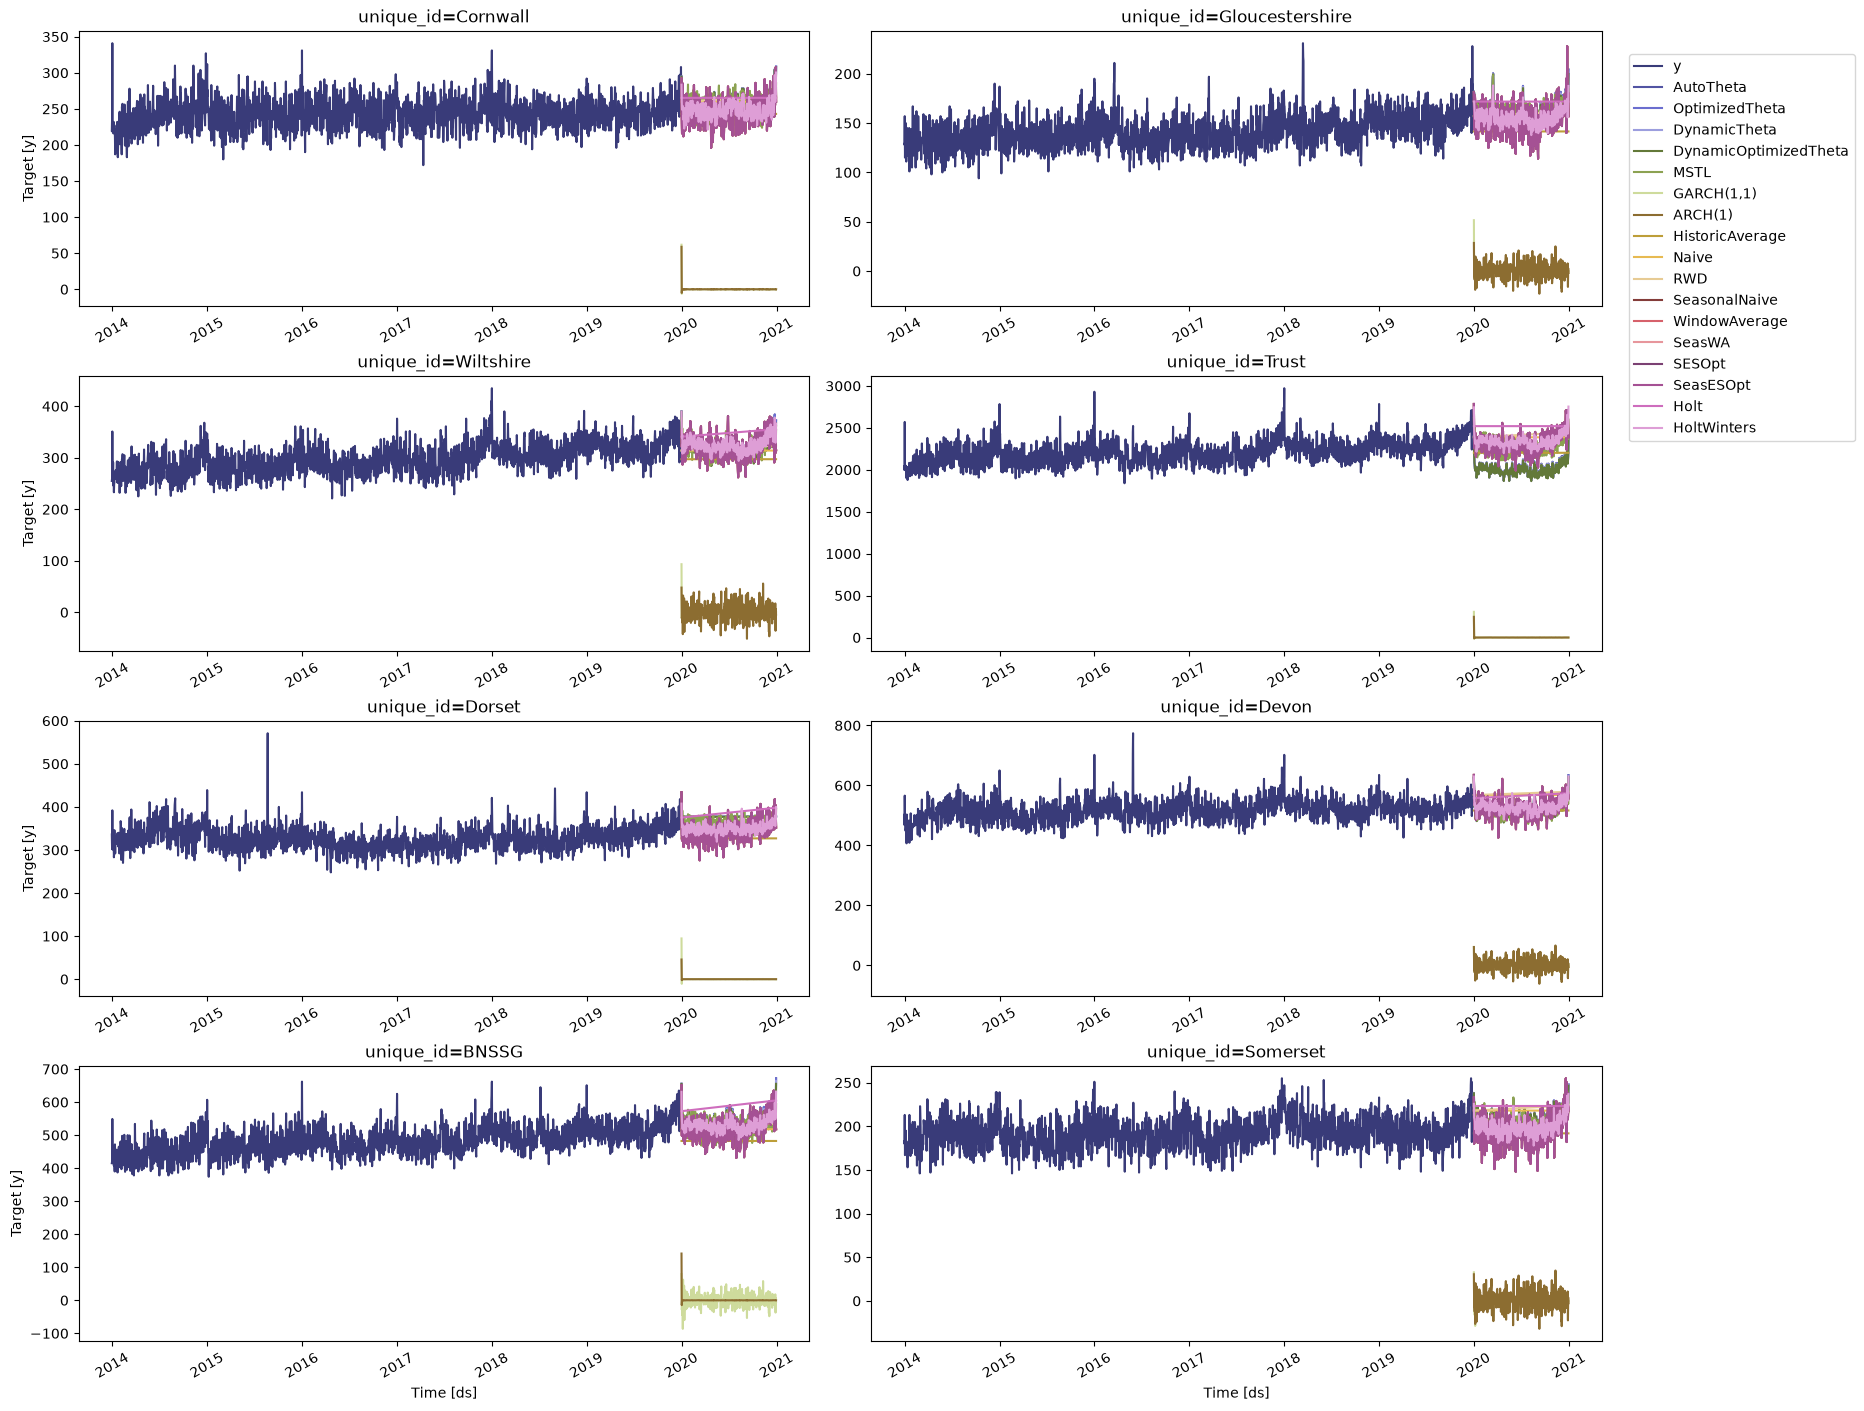

In [5]:
sf.plot(df_filtered,forecasts_df)

In [22]:
#cross validating the models
cv_df = sf.cross_validation(
    df = df_filtered,
    h=365, #forecasts 365 days ahead
    step_size=182, #moves the window 182 days ahead before each forecast
    n_windows=5, #evaluates 7 windows
)

display(cv_df.head())
display(cv_df.tail())


,unique_id,ds,cutoff,y,AutoTheta,OptimizedTheta,DynamicTheta,DynamicOptimizedTheta,MSTL,"GARCH(1,1)",...,HistoricAverage,Naive,RWD,SeasonalNaive,WindowAverage,SeasWA,SESOpt,SeasESOpt,Holt,HoltWinters
0,BNSSG,2017-01-03,2017-01-02,509.0,513.431274,513.431274,513.230652,513.033386,479.838959,66.858742,...,464.063629,536.0,536.110107,485.0,529.428589,470.666656,510.844238,485.000000,511.370361,494.128571
1,BNSSG,2017-01-04,2017-01-02,446.0,513.471497,513.471497,513.251465,513.033813,460.383728,-17.385292,...,464.063629,536.0,536.220215,493.0,529.428589,457.666656,510.844238,492.558197,511.449036,478.191284
2,BNSSG,2017-01-05,2017-01-02,466.0,513.511719,513.511719,513.272339,513.034180,472.532196,-14.888027,...,464.063629,536.0,536.330322,462.0,529.428589,443.666656,510.844238,461.798492,511.527710,459.781433
3,BNSSG,2017-01-06,2017-01-02,464.0,513.551941,513.551941,513.293335,513.034546,459.532227,-30.239872,...,464.063629,536.0,536.440430,445.0,529.428589,408.666656,510.844238,407.053314,511.606354,418.265747
4,BNSSG,2017-01-07,2017-01-02,496.0,513.592163,513.592163,513.314331,513.034973,506.700500,24.423422,...,464.063629,536.0,536.550476,471.0,529.428589,452.666656,510.844238,470.769104,511.685028,467.276031


,unique_id,ds,cutoff,y,AutoTheta,OptimizedTheta,DynamicTheta,DynamicOptimizedTheta,MSTL,"GARCH(1,1)",...,HistoricAverage,Naive,RWD,SeasonalNaive,WindowAverage,SeasWA,SESOpt,SeasESOpt,Holt,HoltWinters
14595,Wiltshire,2019-12-27,2018-12-31,369.0,347.399811,347.399811,342.655304,338.454102,332.967468,-0.067418,...,292.067291,306.0,316.077179,339.0,327.142853,333.333344,332.146362,333.446808,347.773438,340.691986
14596,Wiltshire,2019-12-28,2018-12-31,350.0,324.080292,324.080292,319.641846,315.713074,335.613129,0.113424,...,292.067291,306.0,316.105103,304.0,327.142853,301.333344,332.146362,296.259186,347.815765,318.762177
14597,Wiltshire,2019-12-29,2018-12-31,365.0,313.653320,313.653320,309.345703,305.534058,320.124207,-0.235991,...,292.067291,306.0,316.132996,333.0,327.142853,309.666656,332.146362,292.376617,347.858093,310.524811
14598,Wiltshire,2019-12-30,2018-12-31,310.0,349.269623,349.269623,344.459503,340.204712,335.381104,0.044003,...,292.067291,306.0,316.160919,339.0,327.142853,349.666656,332.146362,318.488342,347.900421,341.946320
14599,Wiltshire,2019-12-31,2018-12-31,314.0,374.103851,374.103851,368.937408,364.369049,324.602539,-0.028518,...,292.067291,306.0,316.188843,306.0,327.142853,331.666656,332.146362,346.593964,347.942780,363.797150


In [ ]:
# scoring each models evaluation 
def evaluate_cv(df_filtered, metric):
    models = df_filtered.columns.drop(['unique_id', 'ds', 'y', 'cutoff']).tolist()
    evals = evaluate(df_filtered, metrics=[metric], models=models)
    evals = evals.drop(columns=['metric'])
    evals['best_model'] = evals[models].idxmin(axis=1)
    return evals

# create a dataframe with the evaluation of cross-validation using a MSE metric
evaluation_df = evaluate_cv(cv_df, mse)
display(evaluation_df.head()) 
display(evaluation_df.tail())


,unique_id,cutoff,AutoTheta,OptimizedTheta,DynamicTheta,DynamicOptimizedTheta,MSTL,"GARCH(1,1)",ARCH(1),HistoricAverage,Naive,RWD,SeasonalNaive,WindowAverage,SeasWA,SESOpt,SeasESOpt,Holt,HoltWinters,best_model
0,BNSSG,2017-01-02,2783.870850,2783.870850,2603.943359,2373.910645,976.923218,233088.718750,233578.828125,1737.874512,4319.153320,6644.234375,1785.983521,3653.812744,1934.151489,2239.692383,1874.235107,3105.245117,2011.974854,MSTL
1,Cornwall,2017-01-02,638.838745,638.838745,642.934143,646.471863,385.326447,60273.277344,60288.417969,457.182068,476.000000,525.872192,645.410950,1230.159302,547.463318,544.202454,622.957642,546.402649,630.598633,MSTL
2,Devon,2017-01-02,1980.896729,1980.896729,1963.668823,1959.563232,1120.740967,272874.937500,272993.218750,1512.608887,2849.493164,3557.568848,2041.147949,4727.489258,1699.079224,3224.630127,1805.924316,3035.437012,1843.015381,MSTL
3,Dorset,2017-01-02,478.199615,478.273193,497.310822,478.199615,788.629028,101317.929688,101317.929688,538.294189,487.926025,570.596252,847.205505,559.322266,726.084961,474.647522,834.565247,484.472565,917.595886,SESOpt
4,Gloucestershire,2017-01-02,319.588104,319.588104,311.997314,300.376709,269.054504,19586.041016,19533.404297,240.944824,239.172607,241.667236,408.690399,341.710907,274.839569,280.162994,391.837830,325.756714,320.856171,Naive


,unique_id,cutoff,AutoTheta,OptimizedTheta,DynamicTheta,DynamicOptimizedTheta,MSTL,"GARCH(1,1)",ARCH(1),HistoricAverage,Naive,RWD,SeasonalNaive,WindowAverage,SeasWA,SESOpt,SeasESOpt,Holt,HoltWinters,best_model
35,Dorset,2018-12-31,544.437012,544.437012,550.321289,544.437012,1165.740479,1.182619e+05,1.183319e+05,917.190491,1074.257568,1169.978394,1256.764404,565.692322,1309.255981,558.703613,1199.775635,561.014709,1216.559448,AutoTheta
36,Gloucestershire,2018-12-31,354.853027,354.853027,365.449402,380.031586,296.651337,2.367810e+04,2.364457e+04,410.034088,238.564377,217.153717,412.961639,210.727036,400.146759,211.354416,433.559814,223.052658,297.535461,WindowAverage
37,Somerset,2018-12-31,367.124542,367.124542,369.832245,377.262360,311.918549,3.841532e+04,3.841970e+04,320.032806,688.602722,808.876465,506.852051,517.219177,333.301971,429.335236,387.426788,429.838196,330.345856,MSTL
38,Trust,2018-12-31,203252.234375,209843.359375,209714.343750,204515.703125,47829.656250,5.341332e+06,5.345874e+06,30851.617188,14617.953125,13225.645508,20934.613281,17082.820312,27117.841797,14214.204102,22752.886719,17426.998047,24660.210938,RWD
39,Wiltshire,2018-12-31,808.344543,808.344543,859.667358,918.589539,886.298645,1.046196e+05,1.044592e+05,1431.175049,766.778076,608.318237,892.586304,500.154633,1149.386841,567.881104,1132.122314,771.768494,755.356934,WindowAverage


In [8]:
# creating a summary table for my evaluation 
# do I need to create a summary table for each unique id though... or should we use the same model for each area. 
evaluation_df['best_model'].value_counts().to_frame().reset_index()

,best_model,count
0,MSTL,18
1,HistoricAverage,8
2,HoltWinters,3
3,WindowAverage,3
4,SESOpt,2
5,Naive,2
6,Holt,2
7,AutoTheta,1
8,RWD,1


,unique_id,best_model
0,BNSSG,MSTL
1,Cornwall,MSTL
2,Devon,MSTL
3,Dorset,SESOpt
4,Gloucestershire,Naive
5,Somerset,MSTL
6,Trust,MSTL
7,Wiltshire,MSTL
8,BNSSG,MSTL
9,Cornwall,MSTL


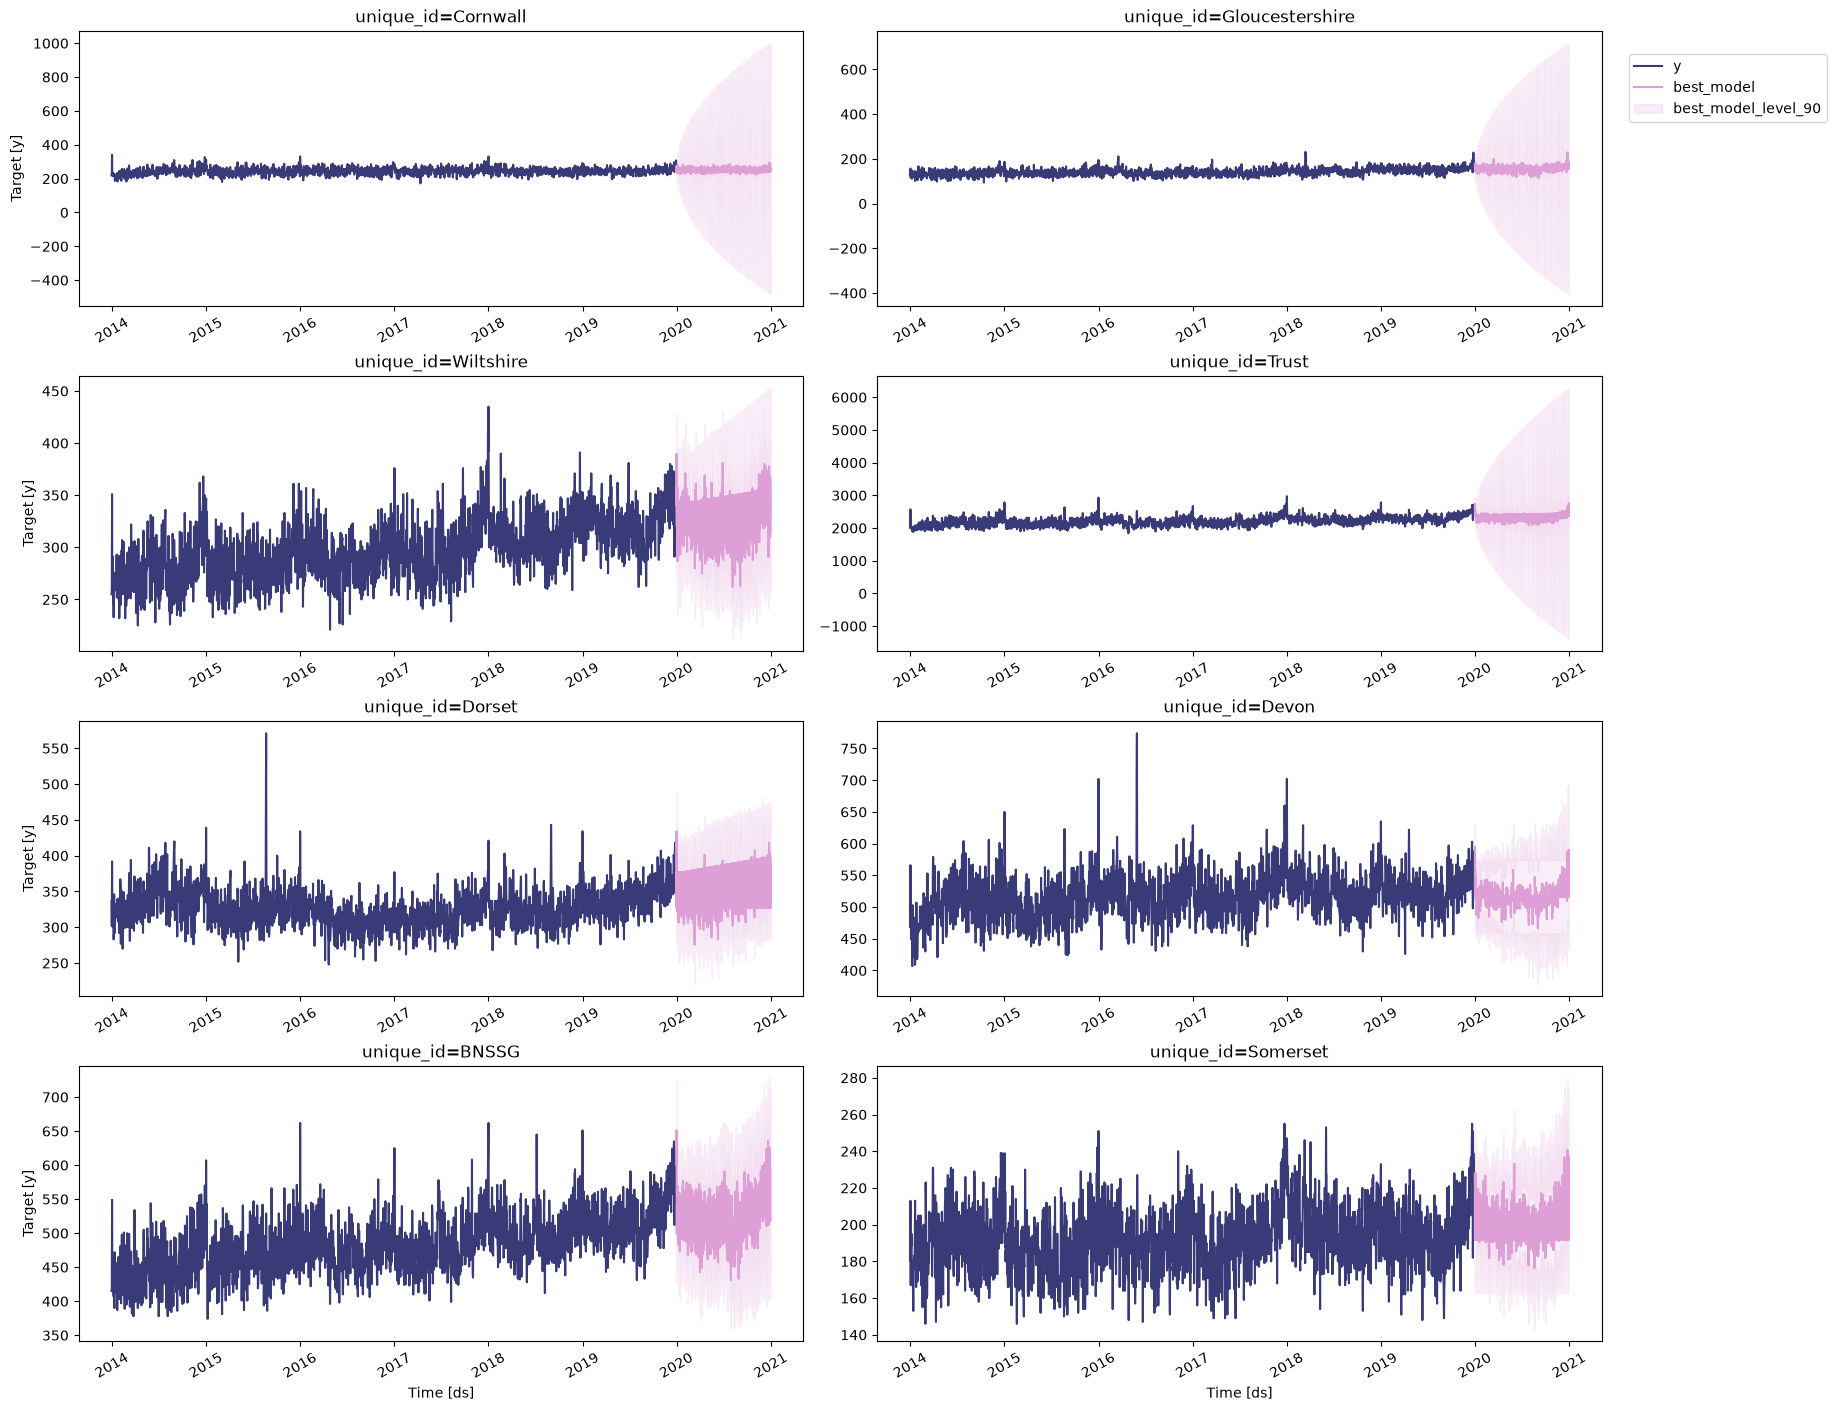

In [ ]:
#making a dataframe with the best possible forecast for each unique_id
def get_best_model_forecast(forecasts_df,evaluation_df):
    with_best=forecasts_df.merge(evaluation_df[['unique_id','best_model']])
    res = with_best[['unique_id','ds']].copy()
    for suffix in ('', '-lo-90','-hi-90'):
        res[f'best_model{suffix}'] = with_best.apply(lambda row: row[row['best_model'] + suffix],axis=1)
    return res

display(evaluation_df[['unique_id', 'best_model']])

prod_forecasts_df = get_best_model_forecast(forecasts_df,evaluation_df)
prod_forecasts_df.head()
StatsForecast.plot(df_filtered,prod_forecasts_df, level=[90])

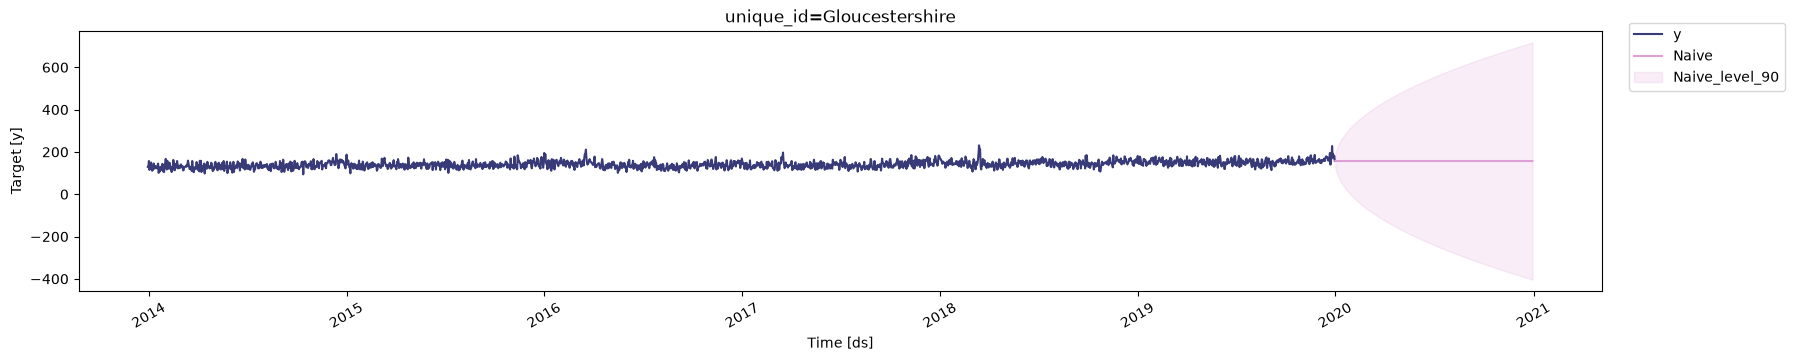

In [ ]:
# inspecting the top 3 models for Cornwall, Gloucestershire and Trust since the plots do not look entirely correct. 
sf.plot(
    df_filtered,
    forecasts_df,
    models=['MSTL'],
    unique_ids=['Cornwall'],
    level=[90]
) 

sf.plot(
    df_filtered,
    forecasts_df,
    models=['Naive'],
    unique_ids=['Gloucestershire'],
    level=[90]
)